
# Unemployment Analysis in India

## Project Overview

This project explores unemployment trends in India using Python.

The analysis focuses on understanding unemployment rates, employment estimates, and labour participation across different regions and areas.

## Objectives

- Explore and understand the unemployment dataset.
- Clean and prepare the data for analysis.
- Analyse unemployment rates across regions.
- Compare unemployment trends in rural and urban areas.
- Visualise key findings using charts.


## 1. Loading the Dataset

We begin by importing Pandas and loading the unemployment dataset.

Pandas allows us to work with structured data in rows and columns.

In [2]:
#import pandas to work with data in table format
import pandas as pd

#load the unemployment dataset
df = pd.read_csv("data/raw/Unemployment in India.csv")

#display the first 5 rows
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



## 2.1 Initial Data Exploration

After loading the dataset, the next step we need to do is to explore its structure and understand the information it contains.

Initial data exploration helps us identify the size of the dataset, the available columns, the data types and whether any values are missing.

This step is important because understanding the quality and structure of the data helps us decide whether cleaning or preparation is required before performing further analysis.

In this section, we will:
- Determine the number of rows and columns.
- Examine the column names.
- Identify the data types.
- Check the number of non-null values in each column.


In [3]:
#display the number of rows and columns
print("Dataset Shape:", df.shape)

#display the column names
print("\nDataset Columns:")
print(df.columns.tolist())

#display information about the dataset
print("\nDataset Information:")
df.info()


Dataset Shape: (768, 7)

Dataset Columns:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1


### 2.2 Checking for Missing Values and Duplicate Records

Data quality is an important part of data analysis. Missing values can affect calculations and produce inaccurate results if they are not handled correctly.

Duplicate records can also affect the analysis by causing certain observations to be counted more than once.

In this section, we will:
- Identify the number of missing values in each column.
- Calculate the total number of missing values.
- Check whether the dataset contains duplicate rows.

This will help us understand the quality of the dataset before cleaning and preparing it for analysis.


In [4]:
#count missing values in each column
print("Missing Values Per Column:")
print(df.isnull().sum())

#calculate the total number of missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

#count duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values Per Column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Total Missing Values:
196

Duplicate Rows:
27



### 2.3 Investigating Empty and Duplicate Rows

The initial data-quality checks identified 28 missing values in every column and 27 duplicate rows.

However, duplicate rows may include completely empty records. Therefore, we need to investigate the dataset further before deciding which records should be removed.

We will:
- Count rows where every column is empty.
- Temporarily exclude completely empty rows.
- Check whether any duplicate records remain.

This helps us avoid accidentally removing valid unemployment observations.


In [5]:
#count rows where all columns are empty
empty_rows = df.isnull().all(axis=1).sum()

print("Completely Empty Rows:", empty_rows)

#temporarily remove completely empty rows for investigation
df_non_empty = df.dropna(how="all")

#check for duplicates among the remaining records
print("\nDuplicate Rows After Excluding Empty Rows:")
print(df_non_empty.duplicated().sum())

#display any remaining duplicate records
print("\nRemaining Duplicate Records:")
df_non_empty[df_non_empty.duplicated(keep=False)].head(10)


Completely Empty Rows: 28

Duplicate Rows After Excluding Empty Rows:
0

Remaining Duplicate Records:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area



### 2.4 Removing Empty Rows and Cleaning Column Names

The investigation we did confirmed that the dataset contains 28 completely empty rows and no duplicate records among the actual observations.

These empty rows do not provide useful information and can be removed without losing valid unemployment data.

We will also remove unnecessary leading and trailing spaces from the column names. This makes the columns easier to reference when writing Python code.

After cleaning, we will check the updated dataset dimensions and confirm that no completely empty rows remain.


In [6]:
#remove completely empty rows
df = df.dropna(how="all")

#remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

#reset the row index after removing empty rows
df = df.reset_index(drop=True)

#display the updated dataset shape
print("Updated Dataset Shape:", df.shape)

#check for remaining completely empty rows
print("\nCompletely Empty Rows:")
print(df.isnull().all(axis=1).sum())

#display cleaned column names
print("\nCleaned Column Names:")
print(df.columns.tolist())

#display the first 5 rows
df.head()


Updated Dataset Shape: (740, 7)

Completely Empty Rows:
0

Cleaned Column Names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



### 2.5 Checking Remaining Missing Values

After removing completely empty rows, we need to identify any remaining missing values in individual columns.

These missing values may affect our analysis, so we will examine them before deciding how to handle them.

We will count the missing values in each column and calculate the total number of missing values in the dataset.


In [7]:
#count missing values in each column
print("Missing Values:")
print(df.isnull().sum())

#calculate total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

Total Missing Values: 0



### 2.6 Converting the Date Column

The Date column is currently stored as a text data type.

For time-based analysis, dates should be converted into a datetime format. This allows us to perform date-related operations, such as sorting records chronologically and analysing unemployment trends over time.

The dates in this dataset follow the day-month-year format (DD-MM-YYYY).

We will convert the Date column into datetime format and verify that the conversion was successful.


In [8]:
#remove extra spaces from date values
df["Date"] = df["Date"].str.strip()

#convert the Date column to datetime format
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

#check the updated data type
print("Date Column Data Type:", df["Date"].dtype)

#display the first 5 dates
df["Date"].head()



Date Column Data Type: datetime64[ns]


0   2019-05-31
1   2019-06-30
2   2019-07-31
3   2019-08-31
4   2019-09-30
Name: Date, dtype: datetime64[ns]

### 2.7 Verifying Data Types and Date Range

After cleaning the dataset and converting the Date column, we need to verify that the data is correctly formatted.

We will examine the data types of all columns and identify the earliest and latest dates recorded in the dataset.

This helps confirm that the dataset is ready for further analysis and shows the period covered by our unemployment data.


In [9]:
#display the data types of all columns
print("Column Data Types:")
print(df.dtypes)

#find the earliest and latest dates
print("\nDate Range:")
print("Start Date:", df["Date"].min())
print("End Date:", df["Date"].max())

#display the unique area categories
print("\nAreas Covered:")
print(df["Area"].unique())

#display the unique data collection frequencies
print("\nData Frequencies:")
print(df["Frequency"].unique())


Column Data Types:
Region                                             object
Date                                       datetime64[ns]
Frequency                                          object
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                               object
dtype: object

Date Range:
Start Date: 2019-05-31 00:00:00
End Date: 2020-06-30 00:00:00

Areas Covered:
['Rural' 'Urban']

Data Frequencies:
[' Monthly' 'Monthly']


### 2.8 Cleaning Text Values

During our initial exploration, we identified inconsistent spacing in the Frequency column.

For example, "Monthly" and " Monthly" are treated as different values by Python, even though they represent the same category.

To maintain consistency, we will remove unnecessary spaces from all text-based columns.

This will help prevent incorrect grouping and counting during our regional and monthly analysis.


In [10]:
#identify all text-based columns
text_columns = df.select_dtypes(include="object").columns

#remove unnecessary spaces from text values
for column in text_columns:
    df[column] = df[column].str.strip()

#display the cleaned frequency values
print("Data Frequencies:")
print(df["Frequency"].unique())

#display the cleaned area values
print("\nAreas:")
print(df["Area"].unique())


Data Frequencies:
['Monthly']

Areas:
['Rural' 'Urban']


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of examining and analysing a dataset to understand its main characteristics, identify patterns and discover relationships between variables.

In this section, we will explore unemployment trends across different regions and time periods in India.

Our analysis will focus on:
- Average unemployment rates across regions.
- Monthly changes in unemployment rates.
- Differences between rural and urban unemployment.
- Relationships between unemployment, employment and labour participation.
- Changes in unemployment before and after the COVID-19 pandemic.

We will use Pandas for data analysis and Matplotlib and Seaborn to create visualisations.


### 3.1 Region-wise Average Unemployment Rate

Understanding unemployment rates across different regions helps identify areas experiencing higher or lower levels of unemployment.

In this section, we group the dataset by region and calculate the average estimated unemployment rate for each region.

The average is calculated using all available observations for each region, including both rural and urban areas.

This will allow us to compare unemployment levels across different regions in India.


In [11]:
#calculate average unemployment rate for each region
region_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

#display average unemployment rates
print("Average Unemployment Rate by Region:")
print(region_unemployment.round(2))


Average Unemployment Rate by Region:
Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Punjab              12.03
Puducherry          10.22
Kerala              10.12
Tamil Nadu           9.28
Goa                  9.27
Chhattisgarh         9.24
West Bengal          8.12
Telangana            7.74
Maharashtra          7.56
Andhra Pradesh       7.48
Madhya Pradesh       7.41
Sikkim               7.25
Karnataka            6.68
Gujarat              6.66
Uttarakhand          6.58
Assam                6.43
Odisha               5.66
Meghalaya            4.80
Name: Estimated Unemployment Rate (%), dtype: float64


### 3.2 Top 10 Regions with the Highest Average Unemployment Rates

To identify the regions most affected by unemployment, we will visualise the 10 regions with the highest average unemployment rates.

A horizontal bar chart makes it easier to compare unemployment levels across regions and identify the areas with the highest averages.

The chart uses the regional averages calculated in the previous section and displays them in descending order.


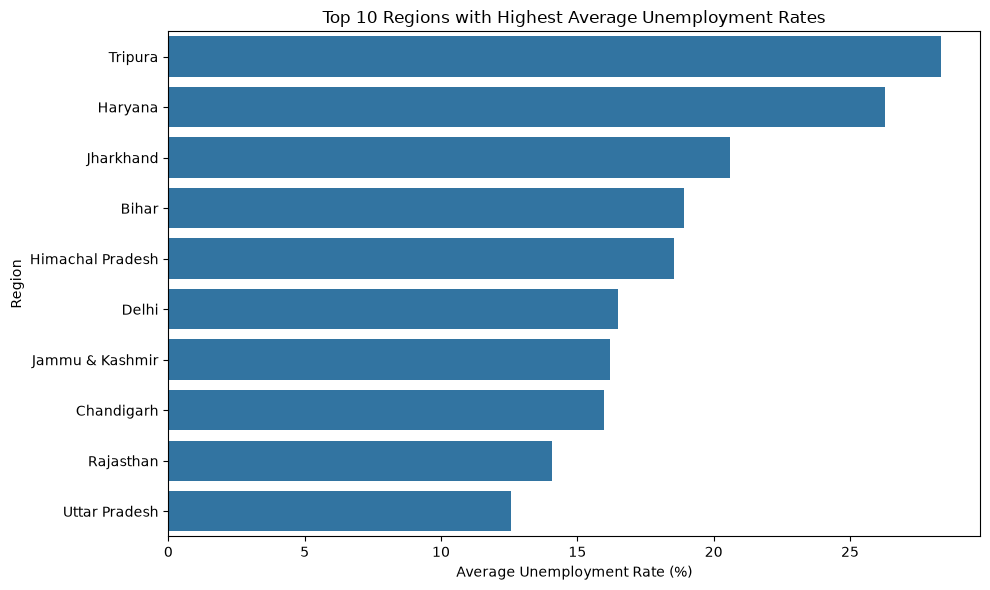

In [ ]:
#import visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

#select the top 10 regions
top_10_regions = region_unemployment.head(10)

#create the bar chart
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_10_regions.values,
    y=top_10_regions.index
)

#add chart title and labels
plt.title("Top 10 Regions with Highest Average Unemployment Rates")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

#display the chart
plt.tight_layout()
plt.show()


**Observations:**

- Tripura has the highest average unemployment rate among the top 10 regions, at approximately 28.35%.
- Haryana follows with an average unemployment rate of 26.28%.
- Jharkhand, Bihar and Himachal Pradesh also have relatively high average unemployment rates.
- Uttar Pradesh completes the top 10, with an average of approximately 12.55%.
- These results show that unemployment levels varied considerably across regions during the period analysed.

The averages combine rural and urban observations from May 2019 to June 2020. They do not represent unemployment rates for a single month.


### 3.3 Monthly Unemployment Trends in India

In this section, we will examine how the average unemployment rate in India changed from May 2019 to June 2020.

We will group the data by month and calculate the average unemployment rate across all regions and both rural and urban areas.

A line chart will help us identify months when unemployment increased or decreased.


In [12]:
#calculate the average unemployment rate for each month
monthly_unemployment = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

#display the monthly average unemployment rates
print("Monthly Average Unemployment Rate:")
print(monthly_unemployment.round(2))


Monthly Average Unemployment Rate:
Date
2019-05-31     8.87
2019-06-30     9.30
2019-07-31     9.03
2019-08-31     9.64
2019-09-30     9.05
2019-10-31     9.90
2019-11-30     9.87
2019-12-31     9.50
2020-01-31     9.95
2020-02-29     9.96
2020-03-31    10.70
2020-04-30    23.64
2020-05-31    24.88
2020-06-30    11.90
Name: Estimated Unemployment Rate (%), dtype: float64


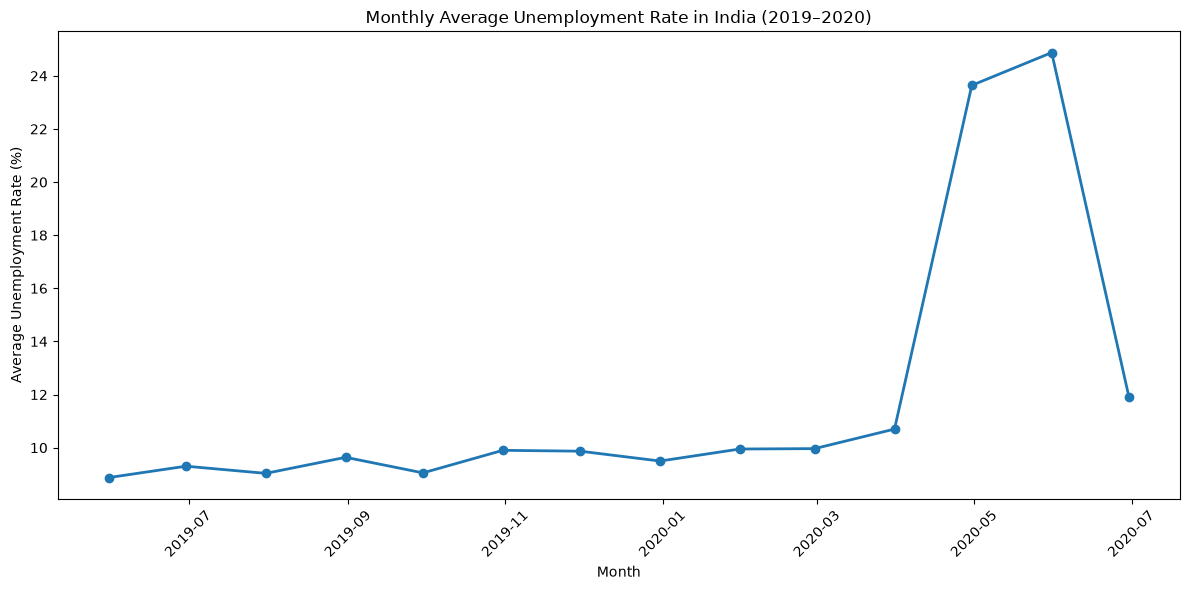

In [ ]:
#create a line chart showing monthly unemployment trends
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o",
    linewidth=2
)

#add chart title and labels
plt.title("Monthly Average Unemployment Rate in India (2019–2020)")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")

#rotate date labels for better readability
plt.xticks(rotation=45)

#display the chart
plt.tight_layout()
plt.show()


**Observations:**

- Unemployment remained relatively stable between May 2019 and February 2020, fluctuating around 9% to 10%.
- A noticeable increase occurred in March 2020, when the average unemployment rate reached 10.70%.
- April 2020 recorded a sharp increase to 23.64%.
- The highest monthly average was recorded in May 2020, at 24.88%.
- In June 2020, the average unemployment rate decreased to 11.90%.

The sharp increase during April and May 2020 coincided with the COVID-19 pandemic and lockdown restrictions in India. The decrease in June suggests a partial recovery, although unemployment remained higher than before the pandemic.


### 3.4 Unemployment Trends Across Selected Regions

In this section, we will compare unemployment rates across three selected regions in India over time.

We will use Haryana, Maharashtra and Tamil Nadu to compare regions with different average unemployment levels.

A line chart will help us observe how unemployment changed in each region between May 2019 and June 2020, including the period during the COVID-19 pandemic.


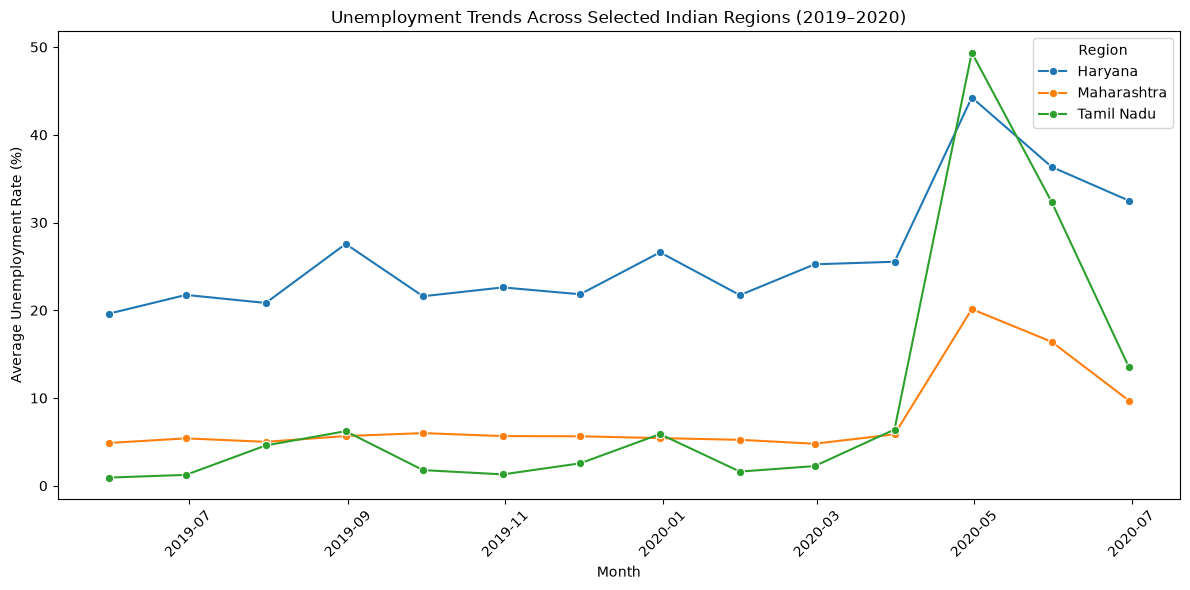

In [ ]:
#select three regions for comparison
selected_regions = ["Haryana", "Maharashtra", "Tamil Nadu"]

#calculate average unemployment rate by date and region
regional_trends = (
    df[df["Region"].isin(selected_regions)]
    .groupby(["Date", "Region"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

#create a line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=regional_trends,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o"
)

#add chart title and labels
plt.title("Unemployment Trends Across Selected Indian Regions (2019–2020)")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")

#rotate date labels
plt.xticks(rotation=45)

#display the chart
plt.tight_layout()
plt.show()


**Observations:**

- Haryana generally experienced higher unemployment rates than Maharashtra and Tamil Nadu during the period analysed.
- Maharashtra showed fluctuations in unemployment, with a noticeable increase during the COVID-19 period.
- Tamil Nadu also experienced an increase in unemployment during 2020.
- All three regions experienced changes in unemployment during the pandemic period.
- The comparison shows that the impact of the pandemic period was not identical across all regions.

These observations are based on monthly averages combining rural and urban data for each selected region.


### 3.5 Correlation Analysis

Correlation analysis helps us understand how numerical variables relate to one another.

In this section, we will examine the relationships between:

- Estimated Unemployment Rate (%)
- Estimated Employed
- Labour Participation Rate (%)

We will use a correlation matrix and heatmap to visualise these relationships.

**Note:** The dataset provides an estimated number of employed people rather than an employment rate. Therefore, we will use the available employment estimate and interpret it as a count, not a percentage.


In [13]:
#select the numerical columns for correlation analysis
correlation_data = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]

#calculate the correlation matrix
correlation_matrix = correlation_data.corr()

#display the correlation values
print("Correlation Matrix:")
print(correlation_matrix.round(2))


Correlation Matrix:
                                         Estimated Unemployment Rate (%)  \
Estimated Unemployment Rate (%)                                     1.00   
Estimated Employed                                                 -0.22   
Estimated Labour Participation Rate (%)                             0.00   

                                         Estimated Employed  \
Estimated Unemployment Rate (%)                       -0.22   
Estimated Employed                                     1.00   
Estimated Labour Participation Rate (%)                0.01   

                                         Estimated Labour Participation Rate (%)  
Estimated Unemployment Rate (%)                                             0.00  
Estimated Employed                                                          0.01  
Estimated Labour Participation Rate (%)                                     1.00  


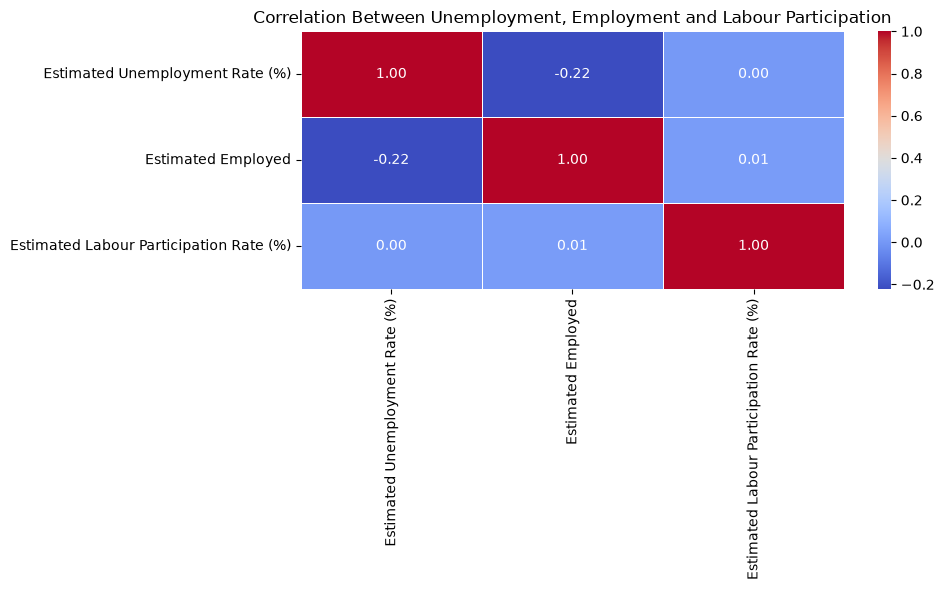

In [ ]:
#create a heatmap to visualise the correlation matrix
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

#add chart title
plt.title("Correlation Between Unemployment, Employment and Labour Participation")

#display the heatmap
plt.tight_layout()
plt.show()


**Observations:**

- The correlation between unemployment rate and estimated employed is -0.22, indicating a weak negative relationship.
- The correlation between unemployment rate and labour participation rate is approximately 0.00, showing almost no linear relationship.
- Estimated employed and labour participation rate have a correlation of 0.01, which also indicates almost no linear relationship.
- Overall, the variables show weak linear relationships in this dataset.

The estimated employed column represents the number of employed people, not an employment percentage. Correlation does not establish that one variable causes changes in another.


### 3.6 Pre-COVID vs Post-COVID Unemployment Comparison

The COVID-19 pandemic affected economic activities and employment across many countries, including India.

In this section, we will compare average unemployment rates before and during the COVID-19 period.

We will use March 2020 as the cutoff date:

- Pre-COVID: May 2019 to February 2020.
- Post-COVID: March 2020 to June 2020.

We will calculate the average unemployment rate for each period and compare the results using a bar chart.

This is a simplified before-and-after comparison. It does not prove that the pandemic was the only cause of changes in unemployment.


In [ ]:
#define the COVID-19 comparison date
covid_start_date = pd.Timestamp("2020-03-01")

#create a copy of the dataset for the comparison
covid_comparison = df.copy()

#classify each record as pre-COVID or post-COVID
covid_comparison["COVID Period"] = covid_comparison["Date"].apply(
    lambda date: "Pre-COVID" if date < covid_start_date else "Post-COVID"
)

#calculate the average unemployment rate for each period
covid_unemployment = (
    covid_comparison.groupby("COVID Period")["Estimated Unemployment Rate (%)"]
    .mean()
)

#display the comparison results
print("Average Unemployment Rate: Pre-COVID vs Post-COVID")
print(covid_unemployment.round(2))


Average Unemployment Rate: Pre-COVID vs Post-COVID
COVID Period
Post-COVID    17.77
Pre-COVID      9.51
Name: Estimated Unemployment Rate (%), dtype: float64


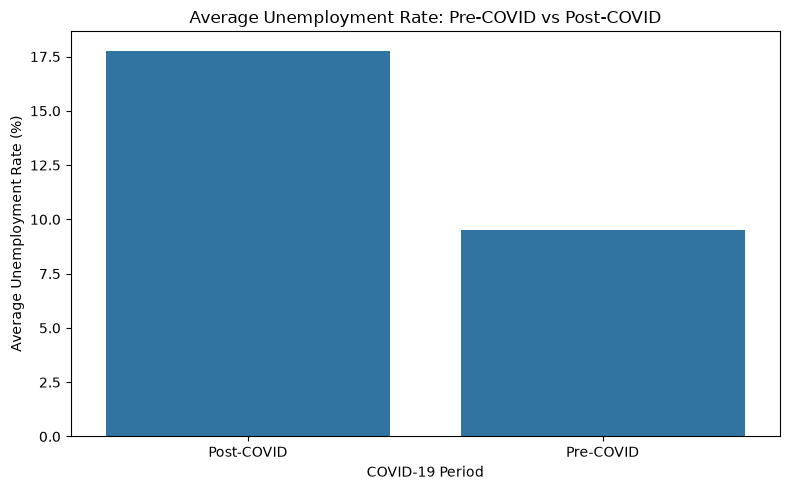

In [ ]:
#create a bar chart comparing unemployment before and during COVID-19
plt.figure(figsize=(8, 5))

sns.barplot(
    x=covid_unemployment.index,
    y=covid_unemployment.values
)

#add chart title and labels
plt.title("Average Unemployment Rate: Pre-COVID vs Post-COVID")
plt.xlabel("COVID-19 Period")
plt.ylabel("Average Unemployment Rate (%)")

#display the chart
plt.tight_layout()
plt.show()


**Observations:**

- The average unemployment rate before COVID-19 was 9.51%.
- During the post-COVID period, the average unemployment rate increased to 17.77%.
- This represents an increase of 8.26 percentage points.
- The results show that unemployment was considerably higher during the period from March to June 2020.
- The increase coincided with the COVID-19 pandemic and lockdown restrictions in India.

This comparison shows an association between the pandemic period and higher unemployment. However, it does not prove that COVID-19 was the only cause of the increase.


# 4. Conclusion and Key Findings

## 4.1 Conclusion

This project explored unemployment trends in India between May 2019 and June 2020 using Python, Pandas, Matplotlib and Seaborn.

The analysis examined regional unemployment rates, monthly trends, differences between selected regions, relationships between numerical variables, and unemployment levels before and during the COVID-19 period.

The main findings were:

1. **Regional differences:** Tripura recorded the highest average unemployment rate at approximately 28.35%, followed by Haryana at 26.28%. Meghalaya recorded the lowest average at 4.80%.

2. **Monthly trends:** Unemployment remained relatively stable between May 2019 and February 2020, generally ranging between 8% and 10%. A sharp increase occurred in April and May 2020.

3. **COVID-19 impact period:** The average unemployment rate increased from 9.51% before March 2020 to 17.77% from March 2020 onwards.

4. **Regional comparisons:** Haryana, Maharashtra and Tamil Nadu experienced different unemployment patterns, showing that unemployment trends varied across regions.

5. **Correlation analysis:** The numerical variables showed weak linear relationships. Unemployment rate and estimated employed had a correlation of -0.22, while unemployment and labour participation had a correlation close to zero.

Overall, the analysis highlights significant regional differences and a substantial increase in unemployment during the COVID-19 period in India.

## 4.2 Tools and Technologies Used

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## 4.3 Skills Demonstrated

- Data loading and cleaning
- Handling missing values and duplicates
- Data type conversion
- Exploratory Data Analysis (EDA)
- Grouping and aggregation
- Data visualisation
- Correlation analysis
- Time-series analysis
- Interpreting data and communicating findings
